In [333]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

from sklearn.cluster import KMeans
from sklearn.metrics import (
silhouette_score,
davies_bouldin_score,
calinski_harabasz_score,
adjusted_rand_score,
normalized_mutual_info_score
)

In [334]:
from threadpoolctl import threadpool_limits

threadpool_limits(limits=2, user_api='openmp')

# Предобработка данных

Приводим датасет к нужному виду

In [335]:
df = pd.read_csv('../digit.dat', sep=';')
df = (df.apply(lambda col: col.str.strip())
      .loc[:, "A":"H"] 
      .replace({"ZERO": 0, "ONE": 1, "zero": 0,
             "one": 1, "two": 2, "three": 3,
             "four": 4, "five": 5, "six": 6,
             "seven": 7, "eight": 8, "nine": 9})
      .astype(int))

df.head()

,A,B,C,D,E,F,G,H
0,7,1,0,1,0,0,1,0
1,1,0,0,1,0,0,1,0
2,4,0,1,1,1,0,1,0
3,2,1,1,1,1,1,0,0
4,8,0,1,1,1,1,1,1


# Разведочный анализ данных

In [336]:
# Применим стили для графиков
plt.style.use('seaborn-v0_8')
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.grid": True,
})

In [337]:
X = df.loc[:, "B":"H"]
y = df["A"]

Посмотрим самые частые комбинации сегментов по цифрам

In [338]:
segments = df.loc[:, 'B':'H'].columns

patterns = (
    df.groupby('A')
    .value_counts(subset=segments, normalize=True)
    .reset_index()
)

patterns['pattern'] = (patterns[segments].astype(str).apply(''.join, axis=1))

summary = (
    patterns.groupby('A')
    .agg(
        top_pattern=('pattern', lambda x: x.iloc[0]),
        n_patterns=('proportion', 'size'),
        max_percent=('proportion', 'max')
    )
)
summary['max_percent'] *= 100

summary.round(1)

,top_pattern,n_patterns,max_percent
A,,,
0,1110111,15,54.8
1,0010010,14,37.2
2,1011101,13,51.2
3,1011011,14,41.8
4,0111010,13,48.1
5,1101011,13,55.6
6,1101111,12,48.0
7,1010010,17,47.9
8,1111111,16,53.4


Посмотрим как выглядят самые частые паттерны

In [339]:
def draw_digit(pattern, ax, title=None):
    
    segments = [
        ((0.2, 1.8), (0.8, 1.8)),  
        ((0.2, 1.8), (0.2, 1.0)), 
        ((0.8, 1.8), (0.8, 1.0)), 
        ((0.2, 1.0), (0.8, 1.0)),
        ((0.2, 1.0), (0.2, 0.2)),
        ((0.8, 1.0), (0.8, 0.2)),
        ((0.2, 0.2), (0.8, 0.2)),
    ]

    for i, flag in enumerate(pattern):
        if int(flag) == 1:
            (x1, y1), (x2, y2) = segments[i]
            ax.plot([x1, x2], [y1, y2], color='black', linewidth=2)
        
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 2)
    ax.axis('off')

    if title is not None:
        ax.set_title(title, fontsize=10)

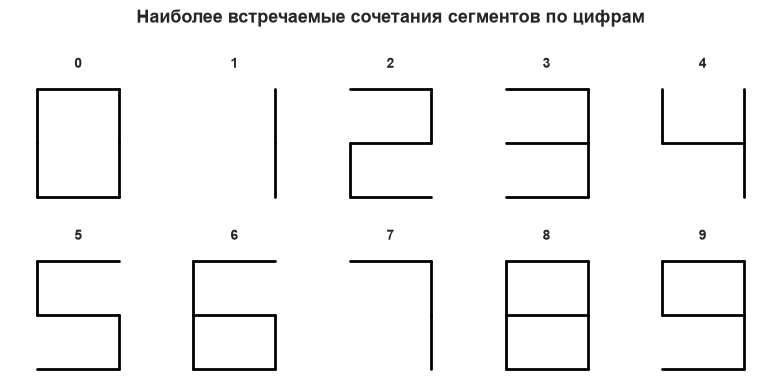

In [340]:
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for digit, ax in zip(range(10), axes.flat):
    draw_digit(summary.at[digit, "top_pattern"], ax, digit)
fig.suptitle("Наиболее встречаемые сочетания сегментов по цифрам", fontsize=13, fontweight='bold')
plt.tight_layout()

Каждая цифра представлена 12–17 уникальными комбинациями сегментов, при этом доля наиболее распространенного паттерна составляет от 37% до 55%. Наиболее частые паттерны соответствуют правильному изображению цифр. Разнообразие паттернов может усложнять кластеризацию, так как объекты одного класса могут различаться между собой, а комбинации сегментов разных классов наоборот могут быть похожи

Проверим сбалансированность исходных классов.

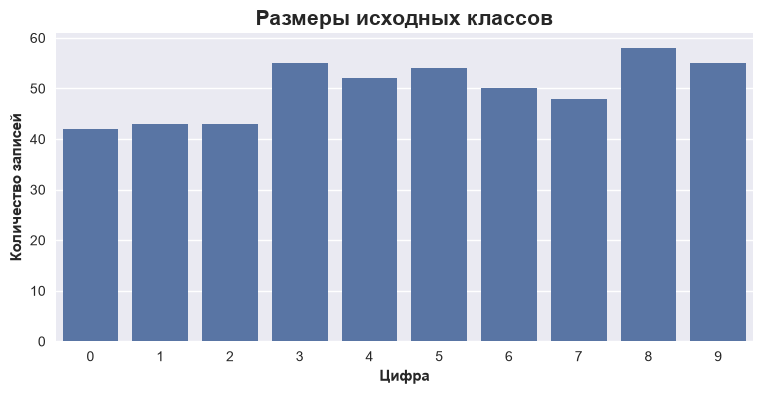

In [341]:
plt.figure(figsize=(9,4))
sns.countplot(x=y)
plt.xlabel("Цифра")
plt.ylabel("Количество записей")
plt.title("Размеры исходных классов")
plt.show()

Нет сильного разброса в размерах исходных классов, что облегчит сопоставление результатов кластеризации с истинными цифрами.

Посмотрим частоту включения сегментов

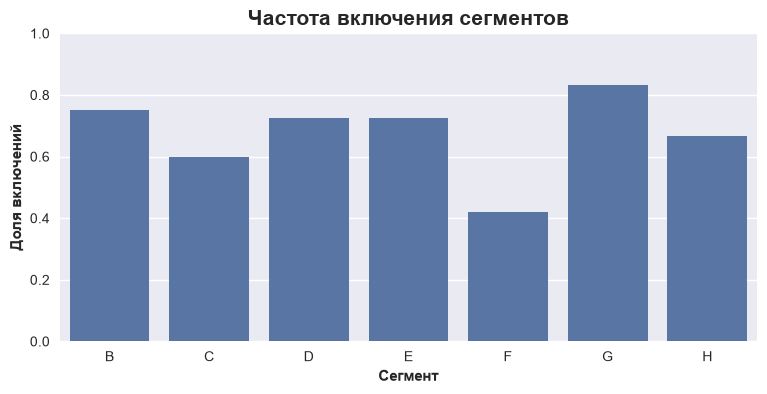

In [342]:
segment_freq = pd.DataFrame(X).mean()

plt.figure(figsize=(9, 4))
sns.barplot(x=X.columns, y=segment_freq.values)
plt.xlabel("Сегмент")
plt.ylabel("Доля включений")
plt.title("Частота включения сегментов")
plt.ylim(0, 1)
plt.show()

Наиболее часто включается сегмент G, реже всего — F. При этом ни один из семи сегментов не является постоянным

# K-means

Зафиксируем сиды рнадома

In [343]:
SEED = 8
rng = np.random.default_rng(SEED)

In [344]:
results = []
k_values = np.arange(2, 16)

Проведем клстеризацию при ранзых K и выберем конкретные K исходя из метрик

In [345]:
for k in k_values:
    n_iter = 0
    
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    
    labels = model.fit_predict(X)
    
    results.append({
        'K': k,
        'inertia': model.inertia_,
        'silhouette': silhouette_score(X, labels),  
        'davies_bouldin': davies_bouldin_score(X, labels),  
        'calinski_harabasz': calinski_harabasz_score(X, labels), 
    })
    
    n_iter = max(model.n_iter_, n_iter)
    
df_results = pd.DataFrame(results)

In [346]:
print(f"Максимальное количество итераций до сходимости: {n_iter}")

Максимальное количество итераций до сходимости: 5


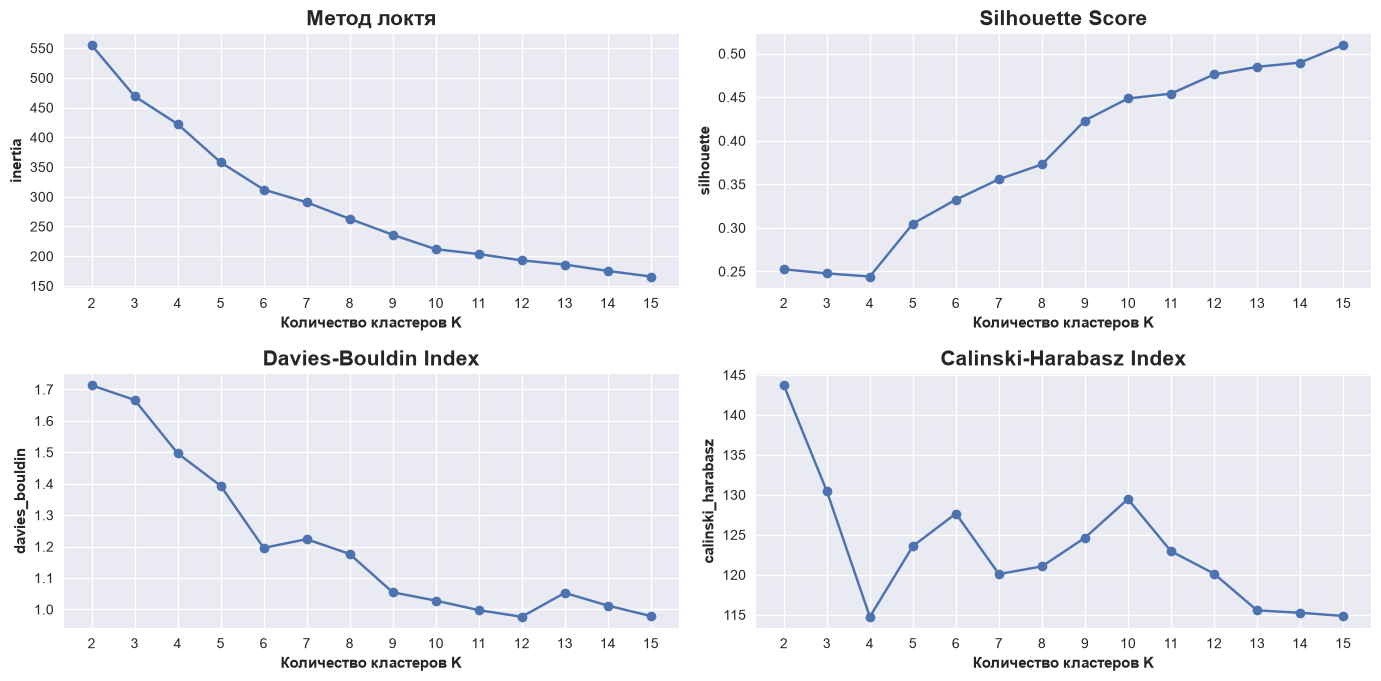

In [347]:
metrics = [
    ('inertia', 'Метод локтя'),
    ('silhouette', 'Silhouette Score'),
    ('davies_bouldin', 'Davies-Bouldin Index'),
    ('calinski_harabasz', 'Calinski-Harabasz Index')
]

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

for ax, (metric, title) in zip(axes.flat, metrics):
    ax.plot(df_results['K'], df_results[metric], marker='o')
    ax.set_title(title)
    ax.set_xlabel('Количество кластеров K')
    ax.set_ylabel(metric)
    ax.set_xticks(df_results['K'])

plt.tight_layout()
plt.show()

Выбор количество кластеров исходя из метрик:
1. Метод локтя: нет перепада, оптимальное количество кластеров не определить
2. График силуэта (больше - лучше): нет локальных максимумов, оптимальное количество кластеров не определить
3. Индекс Дэвиса-Болдина (меньше - лучше): локальный минимум в K=6 и K=12
4. Индекс Калински-Харабаша (больше - лучше): локальные локальные максимумы в K=6 и K=10  
Кластеры должны быть хорошо интерпретируемы, а 12 кластеров из 10 цифр интерпретировать трудно, поэтому далее рассмотрим 6 и 10 кластеров

Посмотрим размеры полученных кластеров при K=6 и K=10

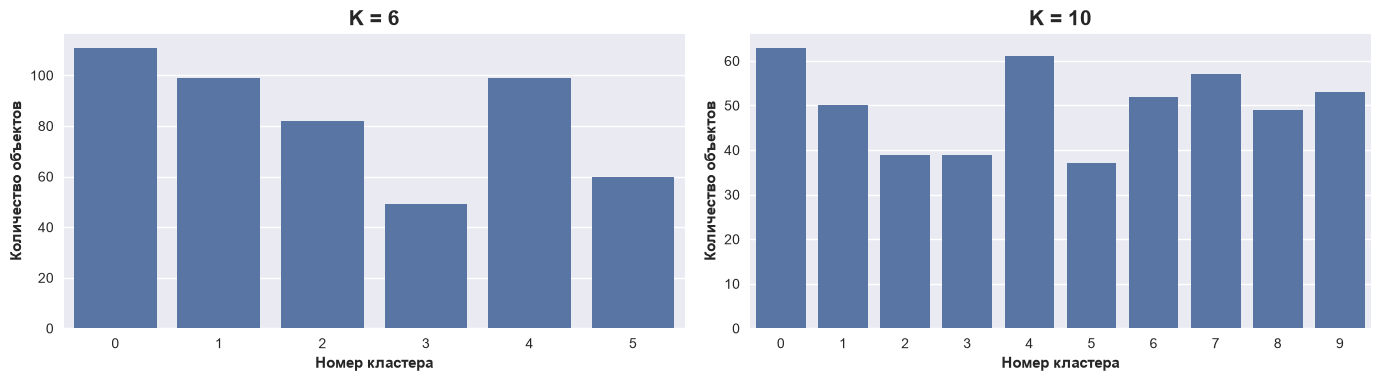

In [348]:
k_values = (6, 10)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

models = {}
cluster_labels = {}

for ax, k in zip(axes.flat, k_values):
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)

    labels = model.fit_predict(X)

    models[k] = model
    cluster_labels[k] = labels
    
    sns.countplot(x=labels, ax=ax)
    ax.set_title(f'K = {k}')
    ax.set_xlabel('Номер кластера')
    ax.set_ylabel('Количество объектов')
    ax.set_xticks(range(k))

plt.tight_layout()
plt.show()

При K=10 размеры кластеров более сбалансированы, при этом очень маленьких кластеров нет

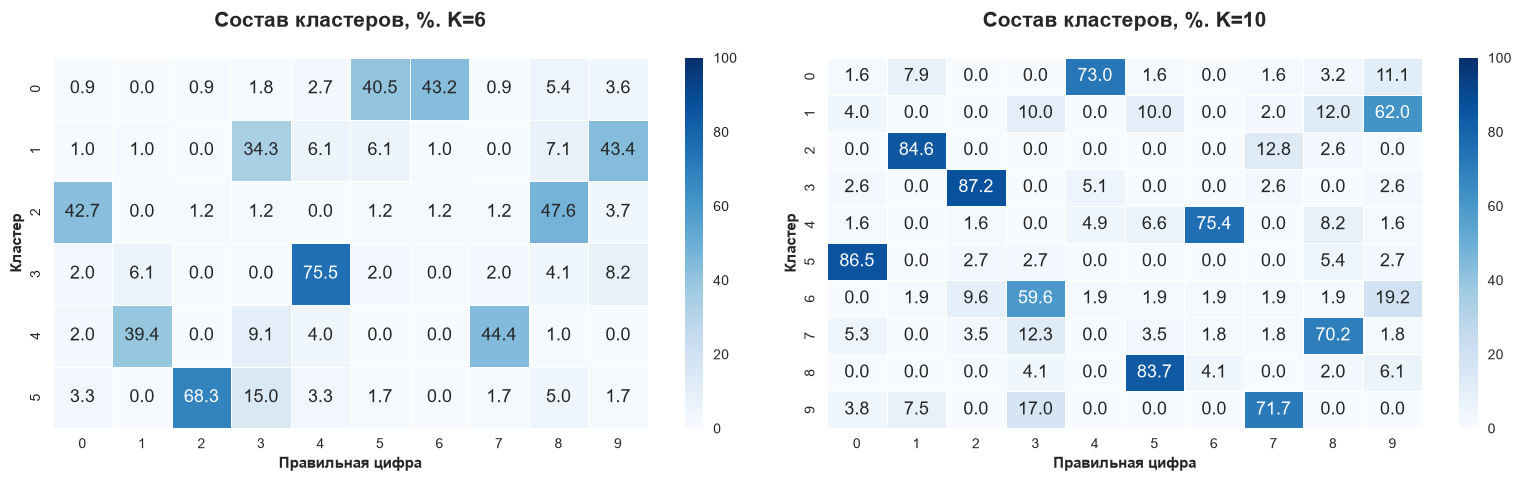

In [349]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for k, ax in zip(k_values, axes.flat):
    table = pd.crosstab(cluster_labels[k], df["A"].to_numpy(), normalize="index") * 100
    sns.heatmap(
        table,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        ax=ax
    )
    ax.set_title(f"Состав кластеров, %. K={k}\n")
    ax.set_xlabel("Правильная цифра")
    ax.set_ylabel("Кластер")
plt.tight_layout()
plt.show()

При K=6 визуально похожие цифры смешиваются в общие кластеры (0 и 8, 1 и 7, 3 и 9, 5 и 6). При K=10 каждому кластеру соответствует отдельная преобладающая цифра.  
Остановимся на выборе 10 кластеров, так как при таком количестве кластеризация показывает более высокое качество по внутренним метрикам. Кроме того такие кластеры лучше соответствуют истинным классам.   

Помотрим координаты центроидов и профили кластеров.

In [350]:
K = 10

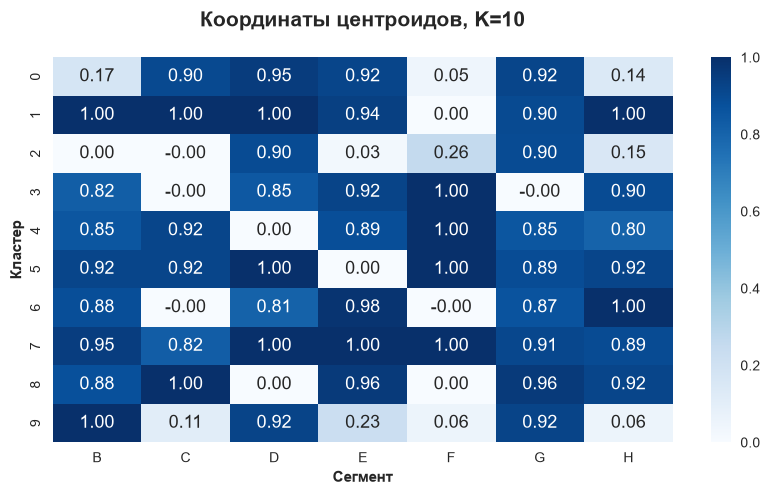

In [351]:
centers = models[K].cluster_centers_

plt.figure(figsize=(10, 5))

sns.heatmap(
    centers,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    xticklabels=X.columns,
    yticklabels=range(K)
)

plt.xlabel('Сегмент')
plt.ylabel('Кластер')
plt.title('Координаты центроидов, K=10\n')
plt.show()

Координаты центроидов имеют значения близкие к 0 или 1, что говорит о наличии характерных комбинаций сегментов внутри кластеров. Профили кластеров достаточно хорошо выражены

На основе центроидов построим типичные изображения цифр для каждого кластера

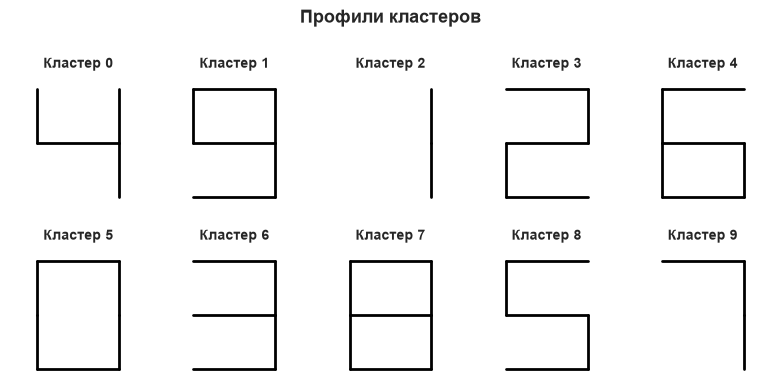

In [352]:
patterns = (centers >= 0.5).astype(int)

fig, axes = plt.subplots(2, 5, figsize=(8, 4))

for i, ax in enumerate(axes.flat):
    draw_digit(patterns[i], ax, title=f'Кластер {i}')
    
fig.suptitle("Профили кластеров", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Каждому из десяти кластеров соответствует отдельная цифра от 0 до 9. Алгоритм смог выделить отдельный кластер для каждой цифры

Построим 3D scatterplot по трем из семи сегментов

In [353]:
def draw_clusters(group):

    centers = models[K].cluster_centers_
    labels = cluster_labels[K]
    
    features = np.argsort(centers[group].var(axis=0))[-3:]
    
    fig = go.Figure()
    
    for cluster in group:
        mask = labels == cluster
        points = X.to_numpy()[mask][:, features]
        points = points + rng.normal(0, 0.03, points.shape)
    
        fig.add_trace(go.Scatter3d(
            x=points[:, 0],
            y=points[:, 1],
            z=points[:, 2],
            mode='markers',
            marker=dict(size=5, opacity=0.3),
            name=f'Кластер {cluster}'
        ))
    
        centroid = centers[cluster, features]
    
        fig.add_trace(go.Scatter3d(
            x=[centroid[0]],
            y=[centroid[1]],
            z=[centroid[2]],
            mode='markers',
            marker=dict(color='black', size=5, symbol='diamond'),
            showlegend=False
        ))
    
    fig.update_layout(
        scene=dict(
            xaxis_title=X.columns[features[0]],
            yaxis_title=X.columns[features[1]],
            zaxis_title=X.columns[features[2]]
        ),
        width=800,
        height=600
    )
    
    fig.show()

In [354]:
draw_clusters([0, 2, 5, 6, 7])

In [355]:
draw_clusters([1, 3, 4, 8, 9])

Запишем итоговые метрики кластеризации

In [356]:
labels = cluster_labels[K]

metrics = pd.DataFrame({
    'Метрика': [
        'Silhouette',
        'Davies-Bouldin',
        'Calinski-Harabasz',
        'ARI',
        'NMI'
    ],
    'Значение': [
        silhouette_score(X, labels),
        davies_bouldin_score(X, labels),
        calinski_harabasz_score(X, labels),
        adjusted_rand_score(df['A'], labels),
        normalized_mutual_info_score(df['A'], labels)
    ]
})
metrics.round(2)

,Метрика,Значение
0,Silhouette,0.45
1,Davies-Bouldin,1.03
2,Calinski-Harabasz,129.47
3,ARI,0.52
4,NMI,0.61
